# ROI_processing

In [1]:
import spatialdata_io
import spatialdata as sd
import troutpy
import scanpy as sc
from spatialdata import SpatialData
import matplotlib.pyplot as plt
from spatialdata.transformations import get_transformation
import matplotlib.patches as patches
import os
import numpy as np
import sys
import seaborn as sns
import hotspot

/home/sergio/.local/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/home/sergio/.local/lib/python3.10/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)
/home/sergio/.local/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)
/home/sergio/.local/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)


In [2]:
# Technology 1: Xenium
sdata = sd.read_zarr("/media/sergio/Meninges/troutpy/rois/xenium_msbrain_5k/data_processed.zarr")
results = sdata["xrna_metadata"].var

In [3]:
troutpy.tl.quantify_overexpression(sdata, codeword_key="control_probe", control_codewords=[True], gene_key="gene",percentile_threshold=99)

In [4]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import spatialdata as sd  # Assuming SpatialData is from this package
from adjustText import adjust_text  # Helps prevent overlapping labels
from scipy.stats import mannwhitneyu, shapiro, ttest_ind

from troutpy.pl import get_colormap, get_palette

def metric_scatter(
    sdata: sd.SpatialData,
    x: str,
    y: str,
    size:int=1,
    non_control_probes: list[str] | None = None,
    label_top_n_x: int = 0,
    label_top_n_y: int = 0,
    label_bottom_n_x: int = 0,
    label_bottom_n_y: int = 0,
    title: str | None = None,
    linewidth:str=0.5,
    figures_path: str = "",
    save: bool = False,
    custom_plot_filename: str = None,
    palette: str = "troutpy",
) -> None:
    """Creates a scatter plot of two specified metrics from a SpatialData object, highlighting control vs. non-control probes, with options to label top genes in each metric and save the figure.

    Parameters
    ----------
    sdata : spatialdata.SpatialData
        A SpatialData object containing 'xrna_metadata' with 'var' DataFrame.
    x : str
        Metric for x-axis.
    y : str
        Metric for y-axis.
    non_control_probes : str
        List of specific non-control probes to include in the plot.
    label_top_n_x : int
        Number of top genes based on x to label.
    label_top_n_y : int
        Number of top genes based on y to label.
    label_bottom_n_x : int
        Number of bottom genes based on x to label.
    label_bottom_n_y : int
        Number of bottom genes based on y to label.
    title : str
        Custom title for the plot.
    figures_path : str
        Directory to save the figure.
    save : bool
        Whether to save the figure.
    custom_plot_filename : str
        Custom filename for the saved plot.
    palette : str
        Color palette for the plot.
    """
    import os

    var_df = sdata["xrna_metadata"].var.copy()

    var_df[x] = var_df[x].replace([np.inf, -np.inf], np.nan)
    var_df[y] = var_df[y].replace([np.inf, -np.inf], np.nan)
    var_df.dropna(subset=[x, y], inplace=True)

    if non_control_probes is not None:
        var_df = var_df[(var_df["control_probe"] is True) | (var_df.index.isin(non_control_probes))]

    # Determine palette
    if palette == "default":
        plot_colors = ["#DC143C", "#1E90FF"]
    else:
        try:
            plot_colors = get_palette(palette)
        except ValueError:
            try:
                cmap = plt.get_cmap(palette)
                plot_colors = [cmap(0), cmap(1)]
            except ValueError:
                print(f"Palette '{palette}' not recognized. Falling back to default colors.")
                plot_colors = ["#DC143C", "#1E90FF"]

    color_map = {True: plot_colors[0], False: plot_colors[1]}
    var_df["plot_color"] = var_df["control_probe"].map(color_map)

    plt.figure(figsize=(6, 6))
    plt.scatter(var_df[x], var_df[y], c=var_df["plot_color"], edgecolor="black", s=size, linewidth=linewidth, alpha=0.9)

    label_genes = set()
    if label_top_n_x > 0:
        label_genes.update(var_df.nlargest(label_top_n_x, x).index)
    if label_top_n_y > 0:
        label_genes.update(var_df.nlargest(label_top_n_y, y).index)
    if label_bottom_n_x > 0:
        label_genes.update(var_df.nsmallest(label_bottom_n_x, x).index)
    if label_bottom_n_y > 0:
        label_genes.update(var_df.nsmallest(label_bottom_n_y, y).index)

    texts = []
    for gene in label_genes:
        texts.append(plt.text(var_df.loc[gene, x], var_df.loc[gene, y], gene, fontsize=11, ha="right", fontweight="bold"))

    x_min, x_max = var_df[x].min(), var_df[x].max()
    y_min, y_max = var_df[y].min(), var_df[y].max()

    x_padding = (x_max - x_min) * 0.1
    y_padding = (y_max - y_min) * 0.1

    plt.xlim(x_min - x_padding, x_max + x_padding)
    plt.ylim(y_min - y_padding, y_max + y_padding)

    adjust_text(
        texts,
        arrowprops={"arrowstyle": "-", "color": "black", "lw": 1},
        only_move={"points": "xy", "text": "xy"},
        expand_points=(4, 4),
        expand_text=(5, 5),
        force_text=(5, 5),
        force_points=(6, 6),
        force_explode=(4, 4),
    )

    plt.xlabel(x.replace("_", " ").title(), fontsize=12, fontweight="bold")
    plt.ylabel(y.replace("_", " ").title(), fontsize=12, fontweight="bold")

    if title:
        plt.title(title, fontsize=14, fontweight="bold")

    # Add legend
    from matplotlib.lines import Line2D

    legend_elements = [
        Line2D([0], [0], marker="o", color="w", label="Control Probe", markerfacecolor=plot_colors[0], markeredgecolor="black", markersize=8),
        Line2D([0], [0], marker="o", color="w", label="Non-Control Probe", markerfacecolor=plot_colors[1], markeredgecolor="black", markersize=8),
    ]
    plt.legend(handles=legend_elements, loc="best", frameon=True)

    plt.xticks(fontsize=10)
    plt.yticks(fontsize=10)

    if save:
        os.makedirs(figures_path, exist_ok=True)
        plot_filename = custom_plot_filename or f"{x}_vs_{y}_scatter.pdf"
        plt.savefig(os.path.join(figures_path, plot_filename), bbox_inches="tight")

    plt.show()


Looks like you are using a tranform that doesn't support FancyArrowPatch, using ax.annotate instead. The arrows might strike through texts. Increasing shrinkA in arrowprops might help.


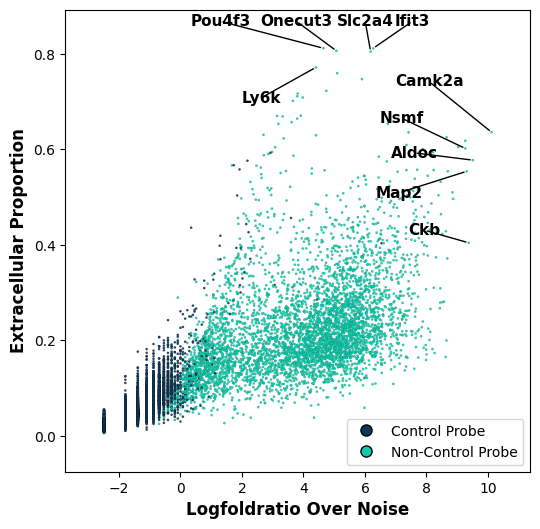

In [5]:
metric_scatter(sdata,x='logfoldratio_over_noise',y='extracellular_proportion',
            label_top_n_x=5,
            label_top_n_y=5,
            label_bottom_n_x=0,
            label_bottom_n_y=0,linewidth=0.05, size=3,
            save=False)

In [6]:
results = sdata["xrna_metadata"].var

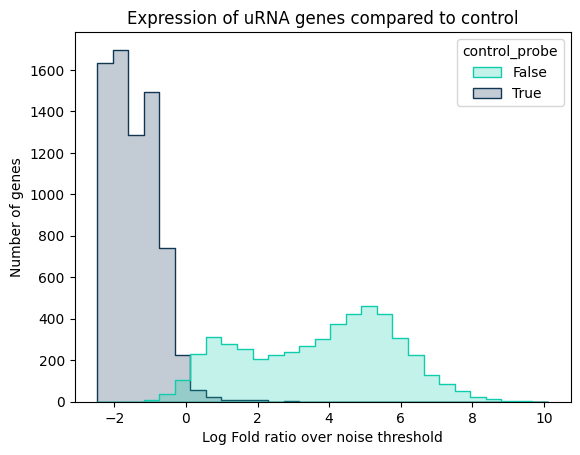

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(data=results, x='logfoldratio_over_noise', hue='control_probe', kde=False, element='step',palette=troutpy.pl.get_palette('troutpy_reversed'))
plt.xlabel('Log Fold ratio over noise threshold')
plt.ylabel('Number of genes')
plt.title('Expression of uRNA genes compared to control')
plt.show()


In [17]:
troutpy.pl.histogram(sdata,x='logfoldratio_over_noise')

KeyError: "None of [Index(['logfoldratio_over_noise'], dtype='object')] are in the [columns]"

In [15]:
results

,count,logfoldratio_over_noise,control_probe,p_value_Poisson,intracellular_proportion,extracellular_proportion,logfoldratio_extracellular,moran_I,moran_pval_norm,moran_var_norm,moran_pval_norm_fdr_bh,in_out_spearmanR,in_out_pvalue,proportion_of_colocalized
Csde1,38204.0,0.618086,False,0.000000,0.782588,0.217412,0.250273,0.015499,0.000000,0.000003,NaN,0.012780,7.199834e-02,9.986667e-02
Apc,46757.0,0.820110,False,0.000000,0.509250,0.490750,-0.993536,0.154023,0.000000,0.000003,NaN,0.045511,1.457306e-10,2.636612e-01
Gpi1,47860.0,0.843426,False,0.000000,0.666674,0.333326,-0.337362,0.040543,0.000000,0.000003,NaN,0.026477,1.932429e-04,1.584833e-01
Fbxl19,26975.0,0.270056,False,0.000000,0.712549,0.287451,-0.122746,0.027395,0.000000,0.000003,NaN,0.042110,3.022137e-09,1.220299e-01
Ppp1r7,19752.0,-0.041599,False,0.000000,0.706663,0.293337,-0.151310,0.022171,0.000000,0.000003,NaN,0.030940,1.322566e-05,9.616485e-02
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
UnassignedCodeword_9697,34.0,-6.406249,True,0.865952,0.970588,0.029412,2.465967,-0.000017,0.499644,0.000003,NaN,NaN,NaN,0.000000e+00
UnassignedCodeword_6017,63.0,-5.789475,True,0.000635,0.952381,0.047619,1.965192,-0.000028,0.497148,0.000003,NaN,NaN,NaN,0.000000e+00
UnassignedCodeword_11107,40.0,-6.243730,True,0.552439,0.925000,0.075000,1.481765,-0.000046,0.492871,0.000003,NaN,NaN,NaN,0.000000e+00
UnassignedCodeword_13172,15.0,-7.224559,True,0.999999,1.000000,0.000000,inf,NaN,NaN,0.000003,NaN,NaN,NaN,6.946811e-310


In [ ]:
sc.pl.umap(sdata['table'],color='leiden',cmap='tab20')

In [ ]:
trans=sdata['transcripts'].compute()
trans['leiden']=trans['leiden'].astype(str)
sdata['transcripts']=sd.models.PointsModel.parse(trans)

In [ ]:
troutpy.pl.spatial_transcripts(sdata,color_key='cosine_similarity',colormap='PuOr')
troutpy.pl.spatial_transcripts(sdata,color_key='match_cell_signature')

In [9]:
sdata

SpatialData object, with associated Zarr store: /media/sergio/Meninges/troutpy/rois/xenium_msbrain_5k/data_processed.zarr
├── Images
│     └── 'morphology_focus': DataTree[cyx] (5, 11300, 16004), (5, 5650, 8002), (5, 2825, 4001), (5, 1412, 2000), (5, 706, 1000)
├── Labels
│     ├── 'cell_labels': DataTree[yx] (11300, 16004), (5650, 8002), (2825, 4001), (1412, 2000), (706, 1000)
│     └── 'nucleus_labels': DataTree[yx] (11300, 16004), (5650, 8002), (2825, 4001), (1412, 2000), (706, 1000)
├── Points
│     ├── 'extracellular_transcripts': DataFrame with shape: (<Delayed>, 21) (3D points)
│     └── 'transcripts': DataFrame with shape: (<Delayed>, 21) (3D points)
├── Shapes
│     ├── 'cell_boundaries': GeoDataFrame shape: (19958, 1) (2D shapes)
│     ├── 'cell_circles': GeoDataFrame shape: (19836, 2) (2D shapes)
│     ├── 'grid_squares': GeoDataFrame shape: (81940, 1) (2D shapes)
│     └── 'nucleus_boundaries': GeoDataFrame shape: (19865, 1) (2D shapes)
└── Tables
      ├── 'segmentation_fr

# Module analysis

In [10]:
adata = sdata["table"]
hs = hotspot.Hotspot(adata, layer_key="raw", model="danb", latent_obsm_key="X_pca", umi_counts_obs_key="total_counts")

hs.create_knn_graph(weighted_graph=False, n_neighbors=20)
hs_results = hs.compute_autocorrelations()
hs_genes = hs_results.loc[hs_results.FDR < 0.001].index  # Select genes
local_correlations = hs.compute_local_correlations(hs_genes, jobs=4)  # jobs for parallelization

100%|███████████████████████████████████████████████████████████████████████████████| 4993/4993 [01:39<00:00, 50.36it/s]


Computing pair-wise local correlation on 4145 features...


100%|█████████████████████████████████████████████████████████████████████| 8588440/8588440 [1:15:38<00:00, 1892.23it/s]


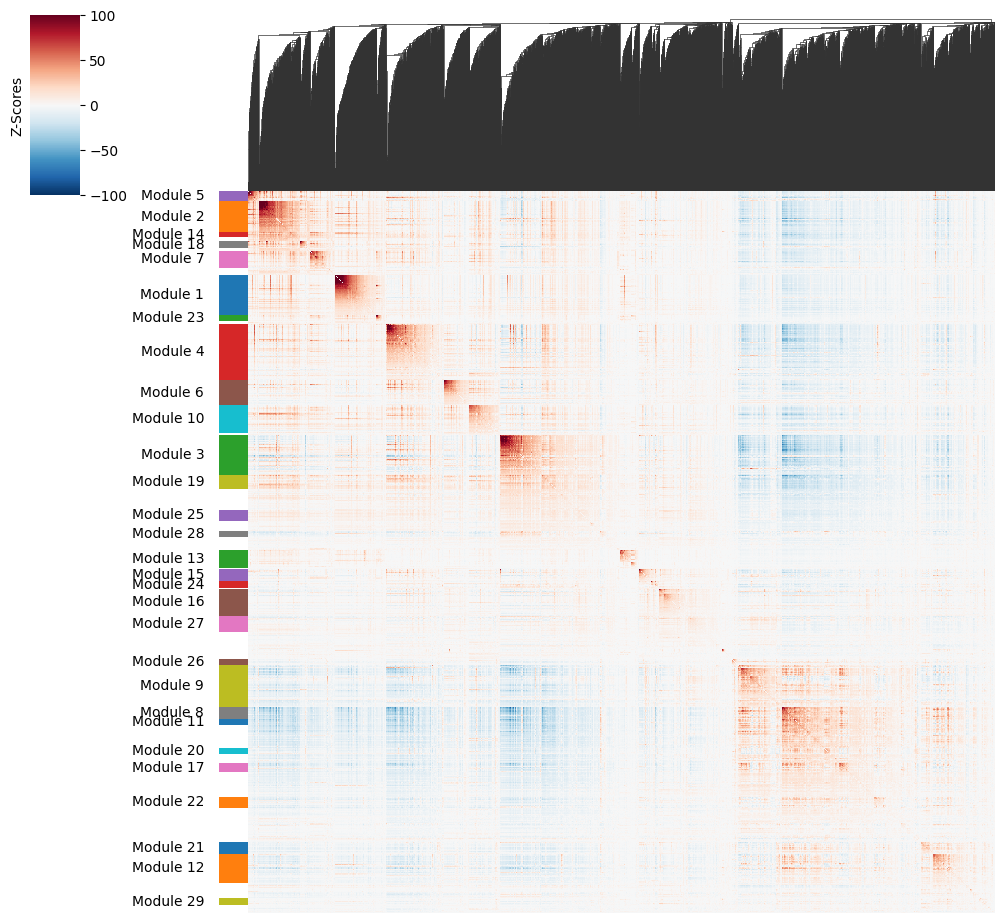

In [13]:
hs.plot_local_correlations(vmax=100, vmin=-100)

In [12]:
# calculate modules
modules = hs.create_modules(min_gene_threshold=30, core_only=True, fdr_threshold=0.0005)
module_scores = hs.calculate_module_scores()

Computing scores for 29 modules...


100%|███████████████████████████████████████████████████████████████████████████████████| 29/29 [00:10<00:00,  2.82it/s]


In [ ]:
adata_scores = sc.AnnData(module_scores, obs=adata.obs)
adata_scores.obsm["X_umap"] = adata.obsm["X_umap"]
adata_scores.obsm["X_pca"] = adata.obsm["X_pca"]
sc.pl.umap(adata, color="leiden")
sc.pl.umap(adata_scores, color=adata_scores.var.index, vmax="p99")

In [16]:
dictmod = dict(zip(modules.index, modules.values))
results["module"] = results.index.map(dictmod)

In [17]:
import matplotlib.pyplot as plt


def annotate_top_bottom(
    df, metric1, metric2, n=5, label_col=None, figsize=(8, 6), scatter_kwargs=None, annotate_kwargs=None, title_tag=""
):
    """
    Scatter-plot df[metric1] vs df[metric2] and annotate the top/bottom n points
    along each axis.

    Parameters
    ----------
    df : pandas.DataFrame
        The data.
    metric1 : str
        Column name for the x-axis metric.
    metric2 : str
        Column name for the y-axis metric.
    n : int, optional (default=5)
        Number of top and bottom points to label per metric.
    label_col : str or None, optional (default=None)
        Column name containing the labels. If None, uses df.index.
    figsize : tuple, optional (default=(8, 6))
        Figure size.
    scatter_kwargs : dict or None
        Extra kwargs passed to plt.scatter().
    annotate_kwargs : dict or None
        Extra kwargs passed to plt.annotate().
    Title tag: str, optional (default='')

    Returns
    -------
    fig, ax : matplotlib.figure.Figure, matplotlib.axes.Axes
        The figure and axes objects.
    """
    # Prepare labels
    df_plot = df.copy()
    if label_col is None:
        df_plot["__idx_label"] = df_plot.index.astype(str)
        label_col = "__idx_label"

    # Plot
    fig, ax = plt.subplots(figsize=figsize)
    sc_kwargs = {} if scatter_kwargs is None else scatter_kwargs
    ax.scatter(df_plot[metric1], df_plot[metric2], **sc_kwargs)
    ax.set_xlabel(metric1)
    ax.set_ylabel(metric2)
    ax.set_title(f"{title_tag}: {metric1} vs {metric2}")

    # Find indices to annotate
    top1 = df_plot.nlargest(n, metric1).index
    bot1 = df_plot.nsmallest(n, metric1).index
    top2 = df_plot.nlargest(n, metric2).index
    bot2 = df_plot.nsmallest(n, metric2).index
    to_annotate = set(top1) | set(bot1) | set(top2) | set(bot2)

    # Annotate
    ann_kwargs = dict(xytext=(5, 5), textcoords="offset points", ha="left", va="bottom", fontsize=8, alpha=0.8)
    if annotate_kwargs:
        ann_kwargs.update(annotate_kwargs)

    for idx in to_annotate:
        x = df_plot.loc[idx, metric1]
        y = df_plot.loc[idx, metric2]
        label = df_plot.loc[idx, label_col]
        ax.annotate(label, xy=(x, y), **ann_kwargs)

    fig.tight_layout()
    return fig, ax

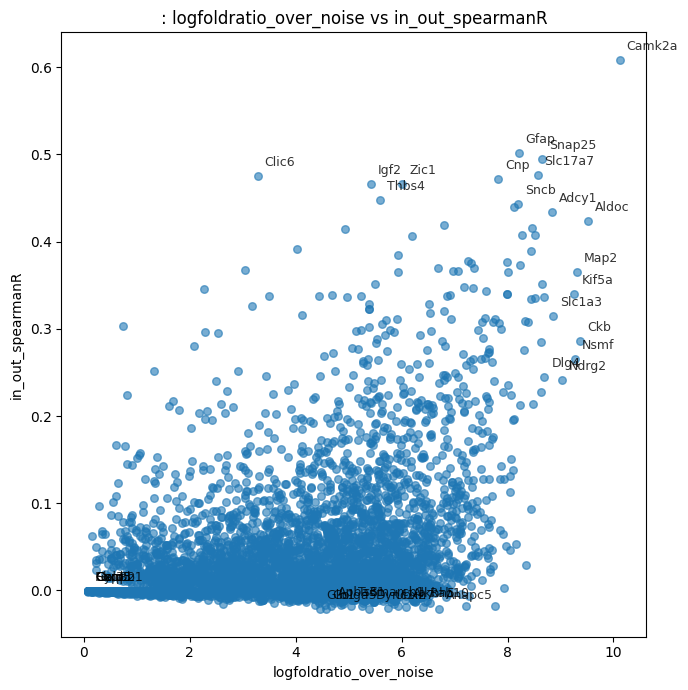

In [18]:
results2 = results[results["logfoldratio_over_noise"] > 0]
fig, ax = annotate_top_bottom(
    df=results2,
    metric1="logfoldratio_over_noise",
    metric2="in_out_spearmanR",
    n=10,
    scatter_kwargs={"alpha": 0.6, "s": 30},
    annotate_kwargs={"fontsize": 9, "color": "black"},
    figsize=(7, 7),
)
plt.show()

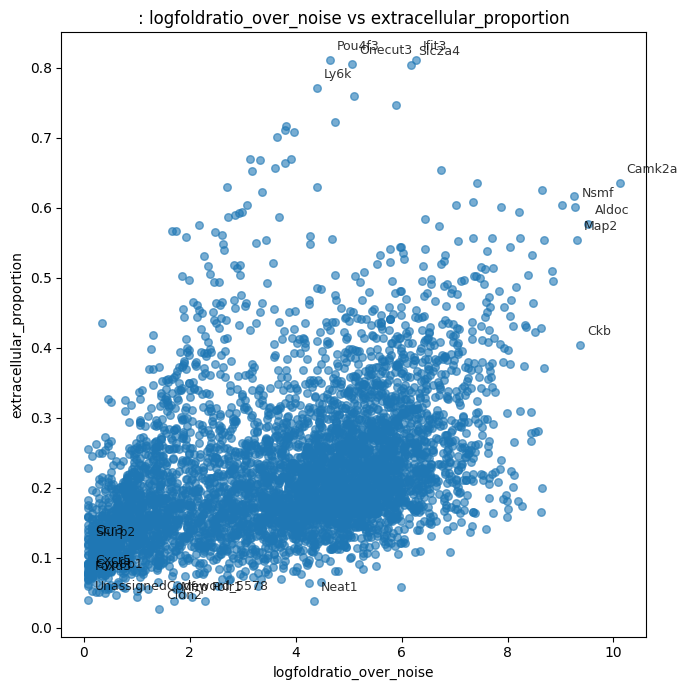

In [19]:
fig, ax = annotate_top_bottom(
    df=results2,
    metric1="logfoldratio_over_noise",
    metric2="extracellular_proportion",
    n=5,
    scatter_kwargs={"alpha": 0.6, "s": 30},
    annotate_kwargs={"fontsize": 9, "color": "black"},
    figsize=(7, 7),
)
plt.show()

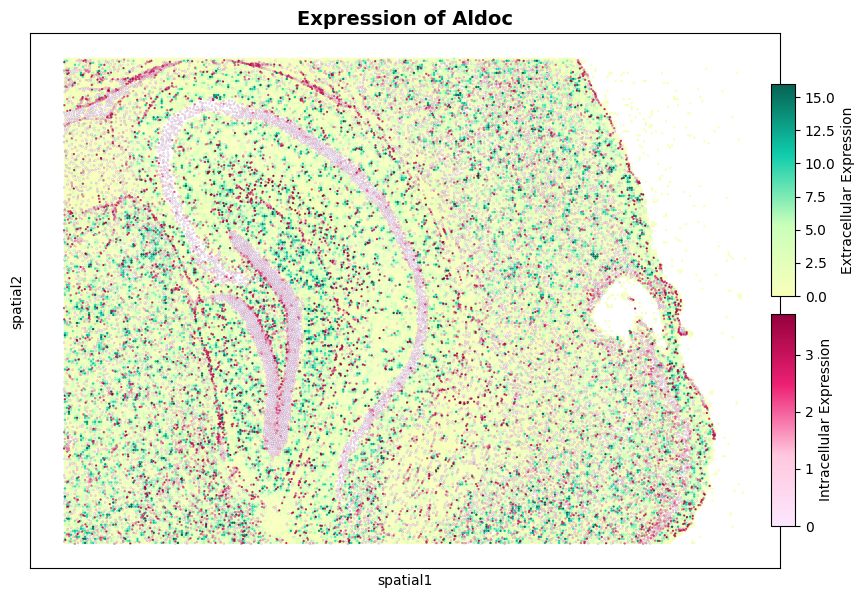

In [72]:
# spatial maps-in out
g2 = "Aldoc"
troutpy.pl.spatial_inout_expression(sdata, g2, spot_size_cells=10)

In [ ]:
sc.pl.umap(adata,color=['Aldoc','Sox9'],vmax='p99',ncols=1,frameon=False)

In [66]:
results_mod4=results[results['module']=='4.0']

In [71]:
results

,intracellular_proportion,extracellular_proportion,logfoldratio_extracellular,moran_I,moran_pval_norm,moran_var_norm,moran_pval_norm_fdr_bh,in_out_spearmanR,in_out_pvalue,proportion_of_colocalized,count,logfoldratio_over_noise,control_probe,p_value_Poisson,module
Csde1,0.782588,0.217412,0.250273,0.015499,0.000000,0.000003,NaN,0.012780,7.199834e-02,0.099867,8306.0,6.539827,False,0.000000,-1.0
Apc,0.509250,0.490750,-0.993536,0.154023,0.000000,0.000003,NaN,0.045511,1.457306e-10,0.263661,22946.0,7.555992,False,0.000000,-1.0
Gpi1,0.666674,0.333326,-0.337362,0.040543,0.000000,0.000003,NaN,0.026477,1.932429e-04,0.158483,15953.0,7.192496,False,0.000000,22.0
Fbxl19,0.712549,0.287451,-0.122746,0.027395,0.000000,0.000003,NaN,0.042110,3.022137e-09,0.122030,7754.0,6.471057,False,0.000000,-1.0
Ppp1r7,0.706663,0.293337,-0.151310,0.022171,0.000000,0.000003,NaN,0.030940,1.322566e-05,0.096165,5794.0,6.179672,False,0.000000,26.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
UnassignedCodeword_9697,0.970588,0.029412,2.465967,-0.000017,0.499644,0.000003,NaN,NaN,NaN,0.000000,1.0,-2.484907,True,0.937082,nan
UnassignedCodeword_6017,0.952381,0.047619,1.965192,-0.000028,0.497148,0.000003,NaN,NaN,NaN,0.000000,3.0,-1.386294,True,0.522386,nan
UnassignedCodeword_11107,0.925000,0.075000,1.481765,-0.000046,0.492871,0.000003,NaN,NaN,NaN,0.000000,3.0,-1.386294,True,0.522386,nan
UnassignedCodeword_13172,1.000000,0.000000,inf,NaN,NaN,0.000003,NaN,NaN,NaN,0.000000,0.0,-inf,True,1.000000,nan


In [ ]:
results.loc[['Scl1a3','Gfap','Sox9'],:]

4.0


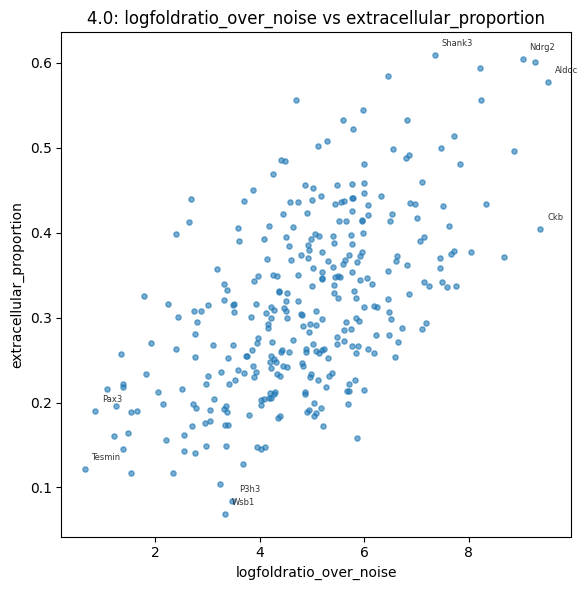

In [74]:
for g, i in results.groupby("module"):
    if float(g) == 4.0:
        print(g)
        # Suppose `results` is your DataFrame and you have a column 'gene' with names:
        fig, ax = annotate_top_bottom(
            df=i,
            metric1="logfoldratio_over_noise",
            metric2="extracellular_proportion",
            n=2,
            scatter_kwargs={"alpha": 0.6, "s": 14},
            annotate_kwargs={"fontsize": 6, "color": "black"},
            title_tag=g,
            figsize=(6, 6),
        )
        plt.show()

In [ ]:
for g, i in results.groupby("module"):
    if float(g) > -1.0:
        print(g)
        # Suppose `results` is your DataFrame and you have a column 'gene' with names:
        fig, ax = annotate_top_bottom(
            df=i,
            metric1="logfoldratio_over_noise",
            metric2="extracellular_proportion",
            n=5,
            scatter_kwargs={"alpha": 0.6, "s": 30},
            annotate_kwargs={"fontsize": 9, "color": "black"},
            title_tag=g,
            figsize=(6, 6),
        )
        plt.show()

In [ ]:
for g, i in results.groupby("module"):
    if g > -1:
        print(g)
        # Suppose `results` is your DataFrame and you have a column 'gene' with names:
        fig, ax = annotate_top_bottom(
            df=i,
            metric1="logfoldratio_over_noise",
            metric2="in_out_spearmanR",
            n=5,
            scatter_kwargs={"alpha": 0.6, "s": 30},
            annotate_kwargs={"fontsize": 9, "color": "black"},
            title_tag=g,
            figsize=(3, 3),
        )
        plt.show()

In [ ]:
mods_df = pd.DataFrame(modules).sort_values(by="Module")
genes = mods_df[mods_df["Module"] == 3].index
sc.pl.umap(adata, color=genes, vmax="p99")
print(genes)

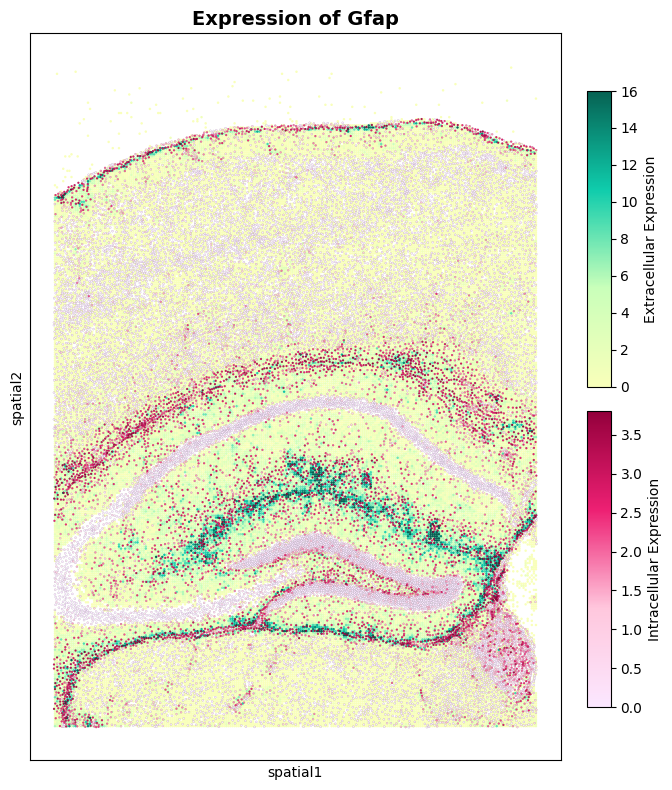

In [51]:
# spatial maps-in out
g2 = "Gfap"
troutpy.pl.spatial_inout_expression(sdata, g2, spot_size_cells=10)

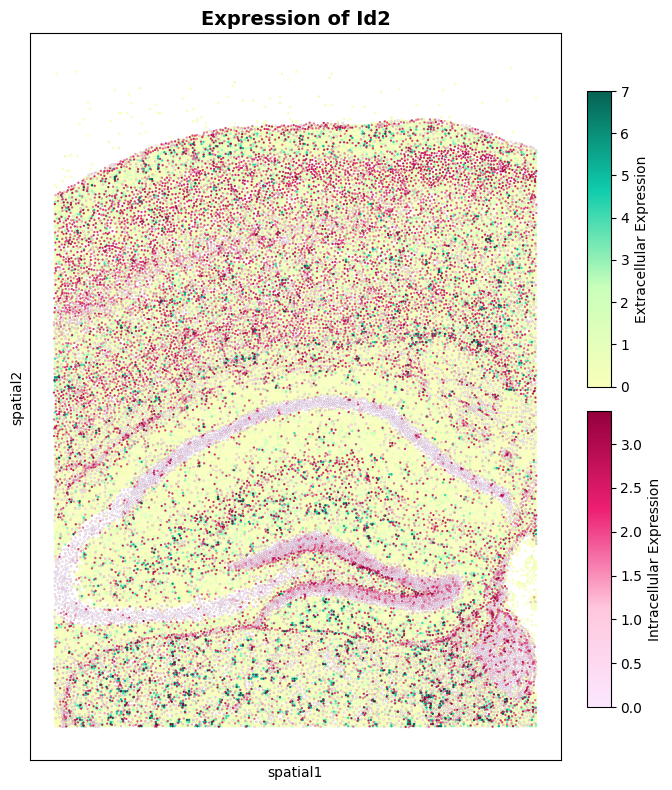

In [52]:
g2 = "Id2"
troutpy.pl.spatial_inout_expression(sdata, g2, spot_size_cells=10)

### Metrics by module

Text(0.5, 1.0, 'logfoldratio_over_noise')

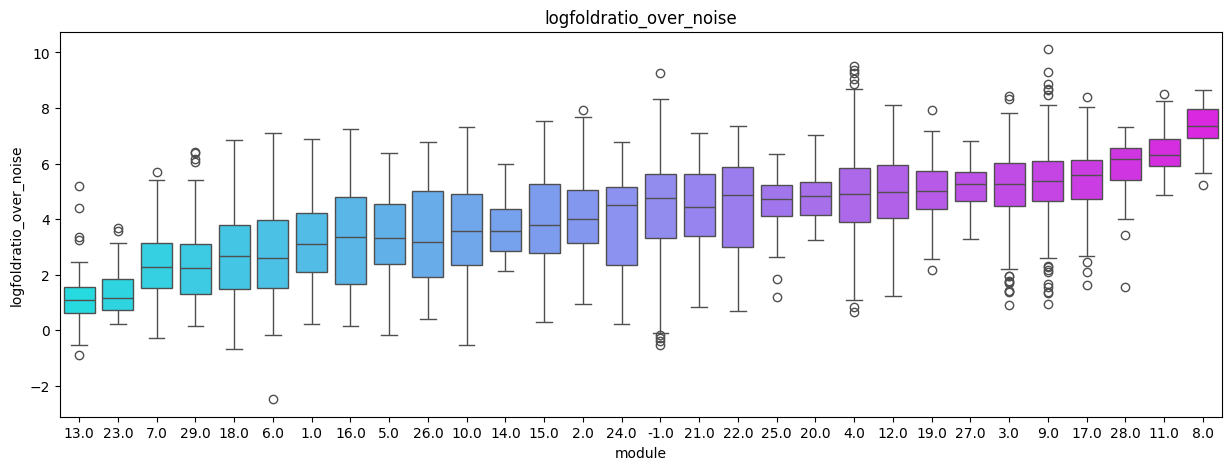

In [22]:
import seaborn as sns
import pandas as pd

variable = "logfoldratio_over_noise"

# Compute the mean logfoldratio_over_noise per module
order = results.groupby("module")[variable].mean().sort_values().index

# Convert 'module' to a categorical variable with the computed order
results["module"] = pd.Categorical(results["module"], categories=order, ordered=True)

plt.figure(figsize=(15, 5))
# Plot with sorted order
sns.boxplot(data=results, x="module", y=variable, hue="module", palette="cool", legend=False)
results["module"] = results["module"].astype(str)
plt.title(variable)

Text(0.5, 1.0, 'extracellular_proportion')

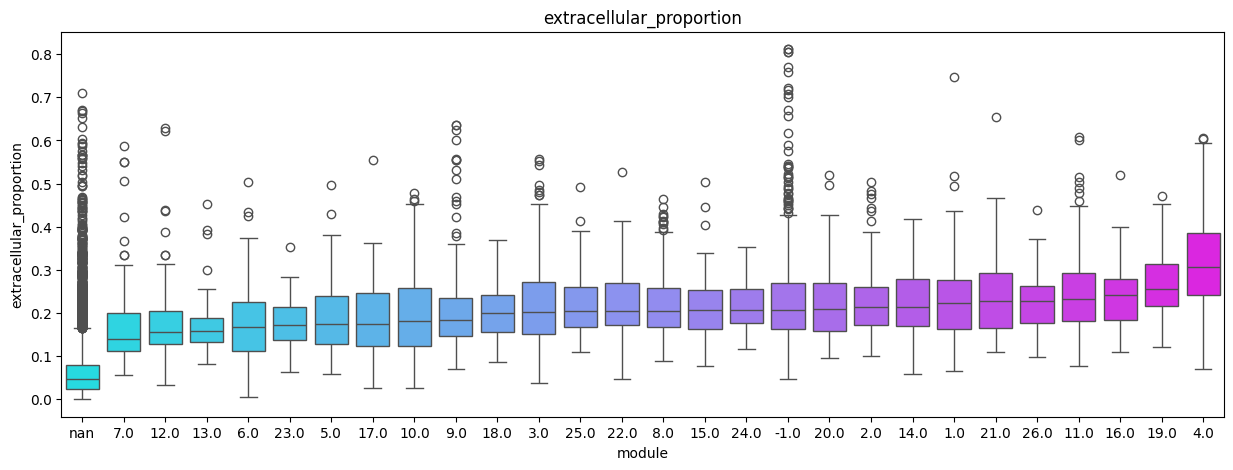

In [36]:
import seaborn as sns
import pandas as pd

variable = "extracellular_proportion"

# Compute the mean logfoldratio_over_noise per module
order = results.groupby("module")[variable].median().sort_values().index

# Convert 'module' to a categorical variable with the computed order
results["module"] = pd.Categorical(results["module"], categories=order, ordered=True)

plt.figure(figsize=(15, 5))
# Plot with sorted order
sns.boxplot(data=results, x="module", y=variable, hue="module", palette="cool", legend=False)
results["module"] = results["module"].astype(str)

plt.title(variable)

In [ ]:
import seaborn as sns
import pandas as pd

variable = "moran_I"

# Compute the mean logfoldratio_over_noise per module
order = results.groupby("module")[variable].median().sort_values().index

# Convert 'module' to a categorical variable with the computed order
results["module"] = pd.Categorical(results["module"], categories=order, ordered=True)
plt.figure(figsize=(15, 5))
# Plot with sorted order
sns.boxplot(data=results, x="module", y=variable, hue="module", palette="cool", legend=False)
results["module"] = results["module"].astype(str)
plt.title(variable)